# Multiple Linear Regression
When we have multiple inputs predict the output

    y = m1x1 + x2x2 + m3x3 + ..... + mnxn + c

When number of variables is 
- 1 - line  
- 2 - plane  
- 3 - hyperplane

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from mpl_toolkits.mplot3d import Axes3D  # For 3D plotting

In [2]:
df = pd.read_csv('../../datasets/Salary_Data.csv')
df.head()

,YearsExperience,Age,Salary
0,1.1,21.0,39343
1,1.3,21.5,46205
2,1.5,21.7,37731
3,2.0,22.0,43525
4,2.2,22.2,39891


In [3]:
df.isnull().sum()

YearsExperience    0
Age                0
Salary             0
dtype: int64

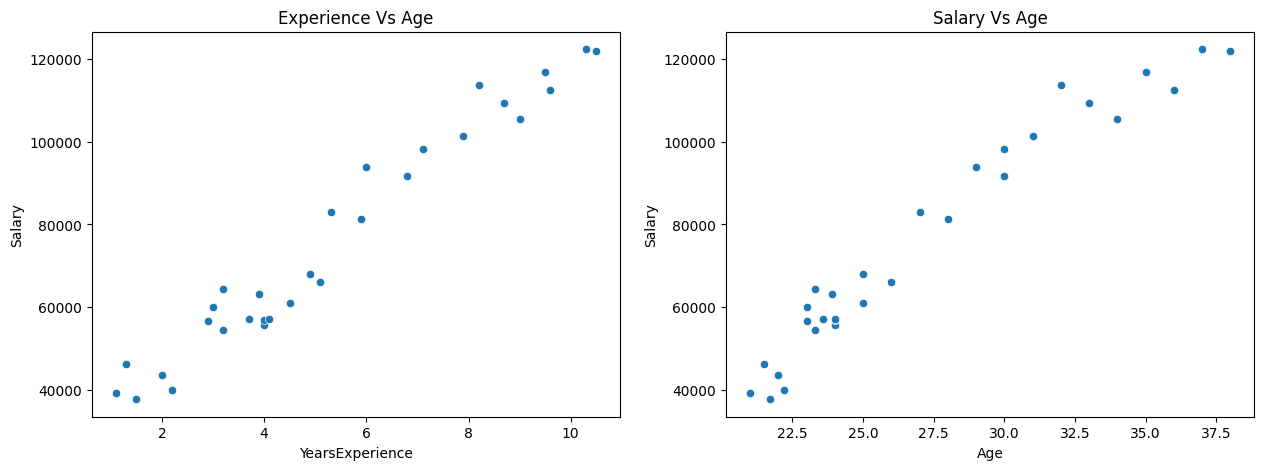

In [4]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plt.title("Experience Vs Age")
sns.scatterplot(x='YearsExperience', y='Salary', data=df)

plt.subplot(1,2,2)
plt.title("Salary Vs Age")
sns.scatterplot(x='Age', y='Salary', data=df)

plt.show()

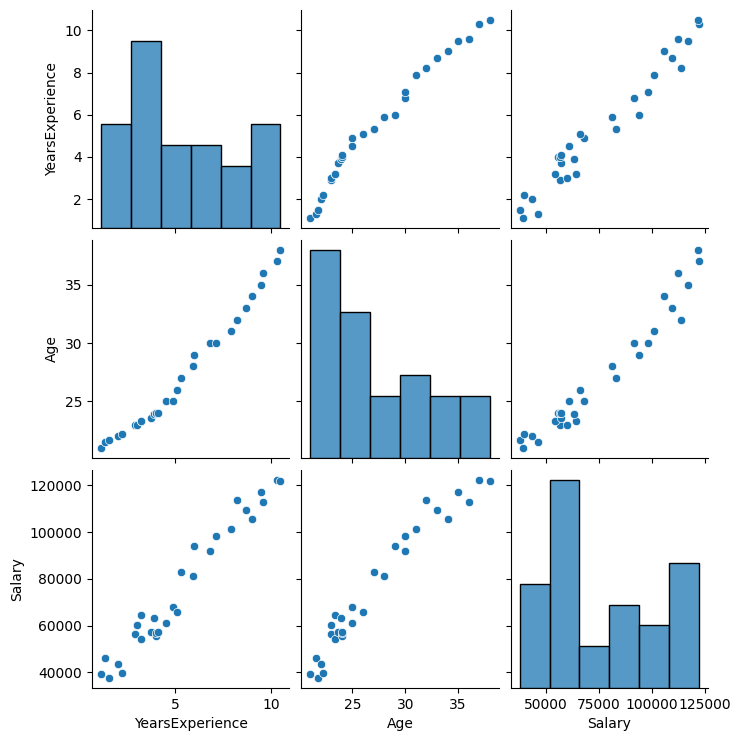

In [5]:
sns.pairplot(data=df)
plt.show()

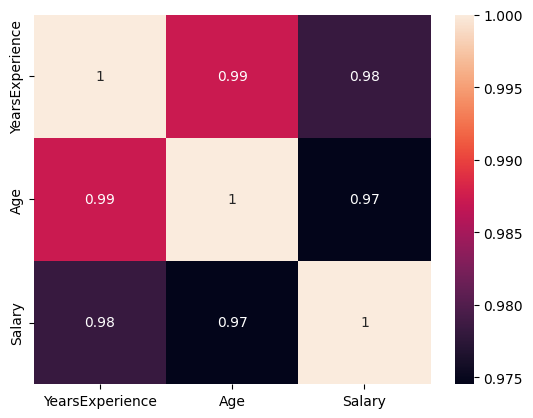

In [6]:
sns.heatmap(data=df.corr(), annot=True)
plt.show()

In [7]:
x = df.iloc[:, :-1]
y = df['Salary']

x.ndim, y.ndim

(2, 1)

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [9]:
lr = LinearRegression()

lr.fit(x_train, y_train)

LinearRegression()

In [10]:
lr.score(x_test, y_test)

0.8852101657216535

In [11]:
lr.predict(x_test)

array([118686.60525402,  67497.80208802, 101581.52273219,  74585.69879684,
        54833.367916  ,  58044.6977654 ])

In [12]:
lr.coef_

array([4882.14850701, 2567.51865301])

In [13]:
lr.intercept_

-20612.691921485326

In [14]:
# y = (m1 * x1) + (m2 * x2) + c

# 1.1	21.0	39343
y_ans = (4882.14850701 * 1.1 ) + (2567.51865301 * 21.0) - 20612.691921485326
y_ans

38675.56314943568

In [15]:
lr.predict([[1.1, 21.0]])

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([38675.56314937])

In [16]:
# x = for visualising
# x_test = for model performance
y_predict = lr.predict(x)

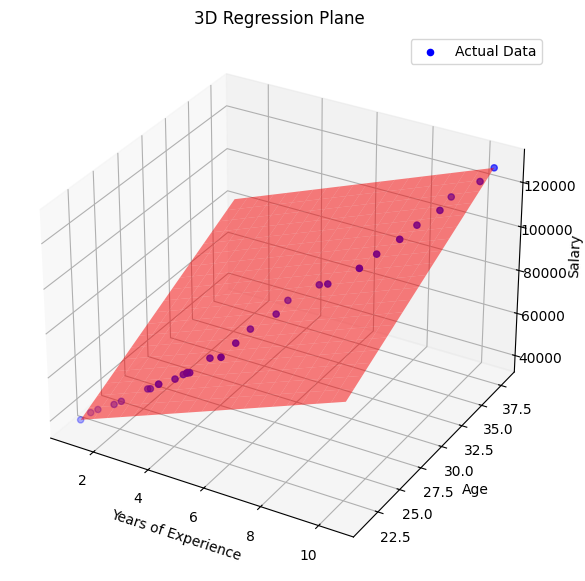

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

X1 = df['YearsExperience']  
X2 = df['Age'] 
Y = y_predict

# Generate mesh grid for plotting the regression plane
x1_range = np.linspace(X1.min(), X1.max(), 20)
x2_range = np.linspace(X2.min(), X2.max(), 20)
X1_grid, X2_grid = np.meshgrid(x1_range, x2_range)
Y_pred = lr.intercept_ + lr.coef_[0] * X1_grid + lr.coef_[1] * X2_grid  # Plane equation

# 3D Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of actual data points
ax.scatter(X1, X2, Y, color='blue', label="Actual Data")

# Regression Plane
ax.plot_surface(X1_grid, X2_grid, Y_pred, alpha=0.5, color='red', )

# Labels
ax.set_xlabel("Years of Experience")  
ax.set_ylabel("Age")  
ax.set_zlabel("Salary")  
ax.set_title("3D Regression Plane")

plt.legend()
plt.show()


---